# Replaying a NASDAQ day from Python

This notebook drives the C++ engine through the `lobpy` bindings. It replays a full ITCH 5.0 day
(NASDAQ BX, 30 July 2019) and gets order book snapshots and trades back as NumPy arrays.

The replay itself runs in C++. Python receives the results without a copy: each array is a view
over a buffer that C++ filled. Install with `pip install ".[notebook]"` from the repo root, and set
`LOB_ITCH_FILE` to the uncompressed ITCH file (see `data/README.md`).

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import lobpy

PATH = os.environ.get("LOB_ITCH_FILE", "../data/20190730.BX_ITCH_50")
SEC = 1_000_000_000
OPEN, CLOSE = (9 * 3600 + 30 * 60) * SEC, 16 * 3600 * SEC

## Snapshots

`snapshots(interval_ns, depth)` samples the top `depth` levels of every chosen book on a fixed time
grid. Here that's every second through regular trading hours, for four of the most active names on
BX that day.

In [2]:
replayer = lobpy.Replayer(PATH, ["SPY", "QQQ", "AAPL", "MSFT"])

t0 = time.perf_counter()
snaps = replayer.snapshots(interval_ns=SEC, depth=5, start_ns=OPEN, end_ns=CLOSE)
elapsed = time.perf_counter() - t0

print(f"replayed the full day in {elapsed:.2f} s")
for name, arr in snaps.items():
    print(f"  {name:10} {str(arr.dtype):6} shape {arr.shape}  zero-copy: {not arr.flags.owndata}")

replayed the full day in 0.25 s
  timestamp  int64  shape (93604,)  zero-copy: True
  symbol     int32  shape (93604,)  zero-copy: True
  bid_price  int64  shape (93604, 5)  zero-copy: True
  bid_size   int64  shape (93604, 5)  zero-copy: True
  ask_price  int64  shape (93604, 5)  zero-copy: True
  ask_size   int64  shape (93604, 5)  zero-copy: True


In [3]:
df = lobpy.snapshots_frame(snaps, replayer.symbols)
df[["time", "symbol", "bid_px_1", "bid_sz_1", "ask_px_1", "ask_sz_1", "mid", "spread"]].iloc[
    4 * 3600 : 4 * 3600 + 8
]

,time,symbol,bid_px_1,bid_sz_1,ask_px_1,ask_sz_1,mid,spread
14400,0 days 10:30:00,SPY,300.38,200,300.44,400,300.410,0.06
14401,0 days 10:30:00,QQQ,193.70,900,193.74,1200,193.720,0.04
14402,0 days 10:30:00,AAPL,207.53,27,207.62,27,207.575,0.09
14403,0 days 10:30:00,MSFT,140.80,240,140.88,100,140.840,0.08
14404,0 days 10:30:01,SPY,300.38,200,300.43,200,300.405,0.05
14405,0 days 10:30:01,QQQ,193.66,1000,193.74,1200,193.700,0.08
14406,0 days 10:30:01,AAPL,207.53,27,207.62,27,207.575,0.09
14407,0 days 10:30:01,MSFT,140.83,100,140.88,100,140.855,0.05


## SPY through the day

The mid price comes from BX's top of book, so it tracks the national price but reflects only
BX's own displayed liquidity. The spread is shown in its own panel, on its own axis.

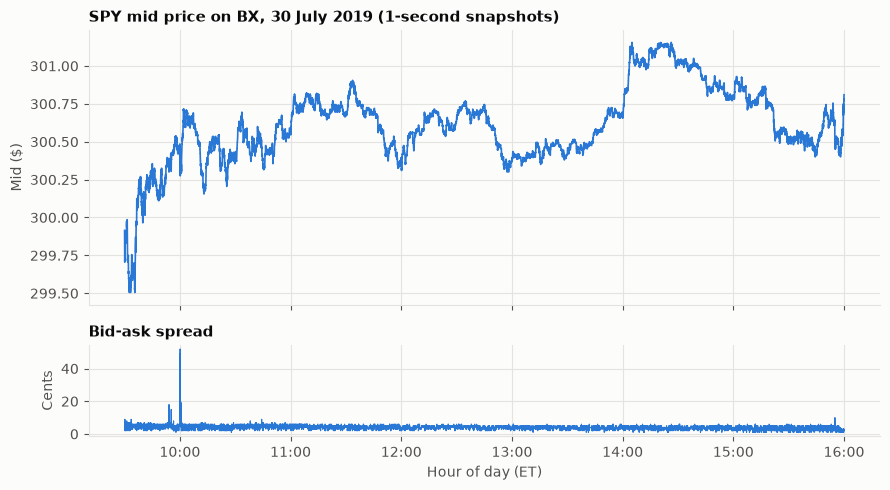

In [4]:
BLUE, RED = "#2a78d6", "#e34948"  # validated palette slots (dataviz reference palette)
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

spy = df[df["symbol"] == "SPY"].set_index("time")
hours = spy.index / pd.Timedelta(hours=1)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 1]})
top.plot(hours, spy["mid"], color=BLUE, linewidth=1.2)
top.set_title("SPY mid price on BX, 30 July 2019 (1-second snapshots)")
top.set_ylabel("Mid ($)")
bottom.plot(hours, spy["spread"] * 100, color=BLUE, linewidth=0.8)
bottom.set_title("Bid-ask spread")
bottom.set_ylabel("Cents")
bottom.set_xlabel("Hour of day (ET)")
bottom.set_xticks(range(10, 17), [f"{h}:00" for h in range(10, 17)])
fig.tight_layout()
plt.show()

## A first look at a signal: order book imbalance

Top-of-book imbalance is (bid size − ask size) / (bid size + ask size), from −1 to +1. If buyers
are queued up, the price tends to tick up next. Below, snapshots are grouped into ten
equal-width imbalance buckets, and each bucket shows the average mid-price move over the
following 10 seconds.

Two choices keep the picture honest on a thin exchange like BX:

- **Equal-width buckets, not deciles.** Imbalance takes a few exact values very often (0 is
  common, since many quotes are 100 vs 100), so quantile bins would collapse into each other.
- **Winsorised moves.** Forward moves are clipped at the 1st and 99th percentiles. The mid
  jumps whenever one side of the book briefly empties, and those jumps would otherwise dominate
  the averages.

This is only a preview of the ML work. It's in-sample, on one day, with no costs. It shows that
the relationship exists, not that it can be traded.

In [5]:
HORIZON = 10  # seconds ahead

df["imbalance"] = (df["bid_sz_1"] - df["ask_sz_1"]) / (df["bid_sz_1"] + df["ask_sz_1"])
future_mid = df.groupby("symbol", observed=True)["mid"].shift(-HORIZON)
df["fwd_bps"] = (future_mid / df["mid"] - 1) * 1e4

sample = df.dropna(subset=["imbalance", "fwd_bps"]).copy()
lo, hi = sample["fwd_bps"].quantile([0.01, 0.99])
sample["fwd_bps"] = sample["fwd_bps"].clip(lo, hi)

edges = np.linspace(-1, 1, 11)
sample["bucket"] = pd.cut(sample["imbalance"], edges, include_lowest=True)
by_bucket = sample.groupby("bucket", observed=False)["fwd_bps"].agg(["mean", "count"])
by_bucket

,mean,count
bucket,,
"(-1.001, -0.8]",-0.482009,1836
"(-0.8, -0.6]",-0.452044,3854
"(-0.6, -0.4]",-1.025067,6840
"(-0.4, -0.2]",-0.310987,7237
"(-0.2, 0.0]",-0.071094,47003
"(0.0, 0.2]",0.106060,4317
"(0.2, 0.4]",0.338569,7488
"(0.4, 0.6]",1.096033,8487
"(0.6, 0.8]",0.692707,4633


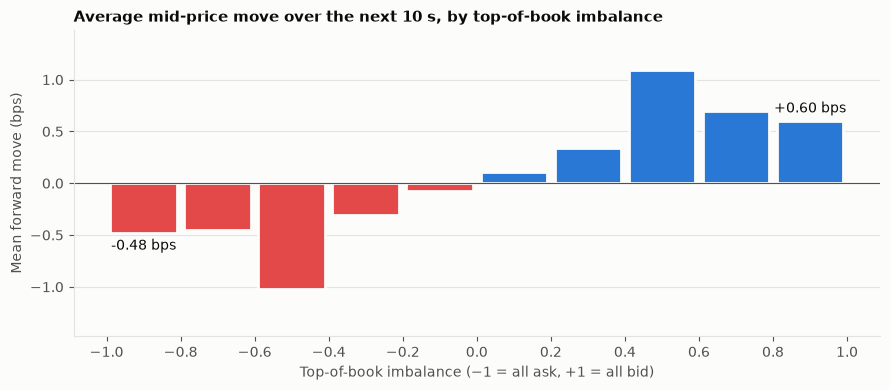

In [6]:
centers = (edges[:-1] + edges[1:]) / 2
means = by_bucket["mean"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 4))
ax.set_axisbelow(True)  # gridlines behind the bars
ax.bar(centers, means, width=0.18, color=[BLUE if v >= 0 else RED for v in means],
       edgecolor=SURFACE, linewidth=2)
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_title(f"Average mid-price move over the next {HORIZON} s, by top-of-book imbalance")
ax.set_xlabel("Top-of-book imbalance (−1 = all ask, +1 = all bid)")
ax.set_ylabel("Mean forward move (bps)")
ax.set_xticks(edges)
ax.grid(axis="x", visible=False)
span = np.nanmax(np.abs(means))
ax.set_ylim(-1.35 * span, 1.35 * span)  # room for the end labels
for i in (0, len(means) - 1):  # label the two extremes only
    v = means[i]
    ax.annotate(f"{v:+.2f} bps", (centers[i], v), ha="center", va="bottom" if v >= 0 else "top",
                xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", color=INK)
fig.tight_layout()
plt.show()

## Trades

`trades()` returns every execution with its **aggressor side**: +1 when a buyer took liquidity,
−1 when a seller did. That trade sign is the input for order-flow features.

In [7]:
trades = lobpy.trades_frame(replayer.trades(), replayer.symbols)
summary = trades.groupby("symbol", observed=True).agg(
    executions=("shares", "size"),
    shares=("shares", "sum"),
    buyer_initiated=("side", lambda s: (s > 0).mean()),
    vwap=("price", lambda p: np.average(p, weights=trades.loc[p.index, "shares"])),
)
summary.round(3)

,executions,shares,buyer_initiated,vwap
symbol,,,,
SPY,3293,736541,0.508,300.543
QQQ,1227,236284,0.416,193.808
AAPL,3210,228723,0.280,209.473
MSFT,2023,180596,0.482,140.546
